# Лабораторная работа № 3
## Кластеризация методом DBSCAN. Леденцы

Найдём группы потребителей с похожими причинами употребления леденцов. По заданию сегменты должны быть понятными, измеримыми и достаточно большими. Используем те же анкеты, что в первых двух работах, но рассчитываем всё заново.

В DBSCAN число кластеров заранее не задаётся: оно зависит от выбранного радиуса соседства и требования к плотности. Часть ответов может остаться вне кластеров. Нужно обосновать параметры, описать найденные группы и отдельно разобраться с такими наблюдениями.

In [1]:
from pathlib import Path
from importlib.metadata import version
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 15)

print("Python:", platform.python_version())
print("; ".join(f"{name}: {version(name)}" for name in
                ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn"]))

Python: 3.14.6
numpy: 2.4.6; pandas: 3.0.3; scipy: 1.18.0; scikit-learn: 1.9.0; matplotlib: 3.11.0; seaborn: 0.13.2


### 1. Данные

Одна строка - ответы одного респондента. Признаки V1–V11 показывают, насколько он согласен с разными причинами употребления леденцов:

| Признак | Причина |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса |
| V5 | Заменить другие кондитерские изделия |
| V6 | Съесть что-нибудь сладкое |
| V7 | Сконцентрироваться |
| V8 | Отвлечься и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

Сначала загрузим таблицу и проверим, есть ли пропуски и повторяющиеся ответы.

In [2]:
def load_data(path, sep=";"):
    """Прочитать таблицу: path — путь к файлу, sep — разделитель полей."""
    return pd.read_csv(path, sep=sep)


data_path = Path("Леденцы.dat")
data = load_data(data_path)

display(data.head())
print("Размер таблицы:", data.shape)
print("Типы столбцов:", data.dtypes.astype(str).value_counts().to_dict())
print("Пропуски:", data.isna().sum().sum())
print("Повторные строки:", data.duplicated().sum())
print("Разные профили ответов:", len(data.drop_duplicates()))
print("Наблюдаемые оценки:", np.unique(data))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Размер таблицы: (338, 11)
Типы столбцов: {'int64': 11}
Пропуски: 0
Повторные строки: 293
Разные профили ответов: 45
Наблюдаемые оценки: [2 3 4 5]


В таблице **338 респондентов и 11 вопросов**, пропусков нет, встречаются оценки 2, 3, 4 и 5. Расшифровка отдельных баллов в условии не дана, поэтому тройку не называем нейтральным ответом.

Разных наборов ответов 45, ещё 293 строки повторяют ранее встретившиеся профили. Сохраняем всех респондентов: одинаковые ответы сами по себе не являются ошибкой. Для DBSCAN это особенно важно, поскольку повторы входят в число соседей и влияют на плотность. Удалить их без учёта частот означало бы изменить задачу.

Основной расчёт проведём на исходных оценках общей шкалы. Как и раньше, принимаем равные интервалы между баллами как приближение для порядковых данных. В конце проверим, что меняется после стандартизации.

Покажем распределения оценок и матрицу Спирмена. Первая карта содержит количества ответов, вторая — связи между вопросами.

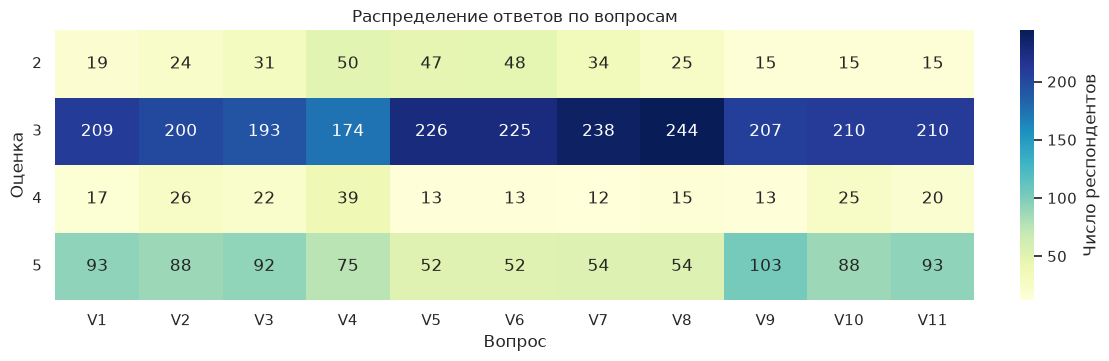

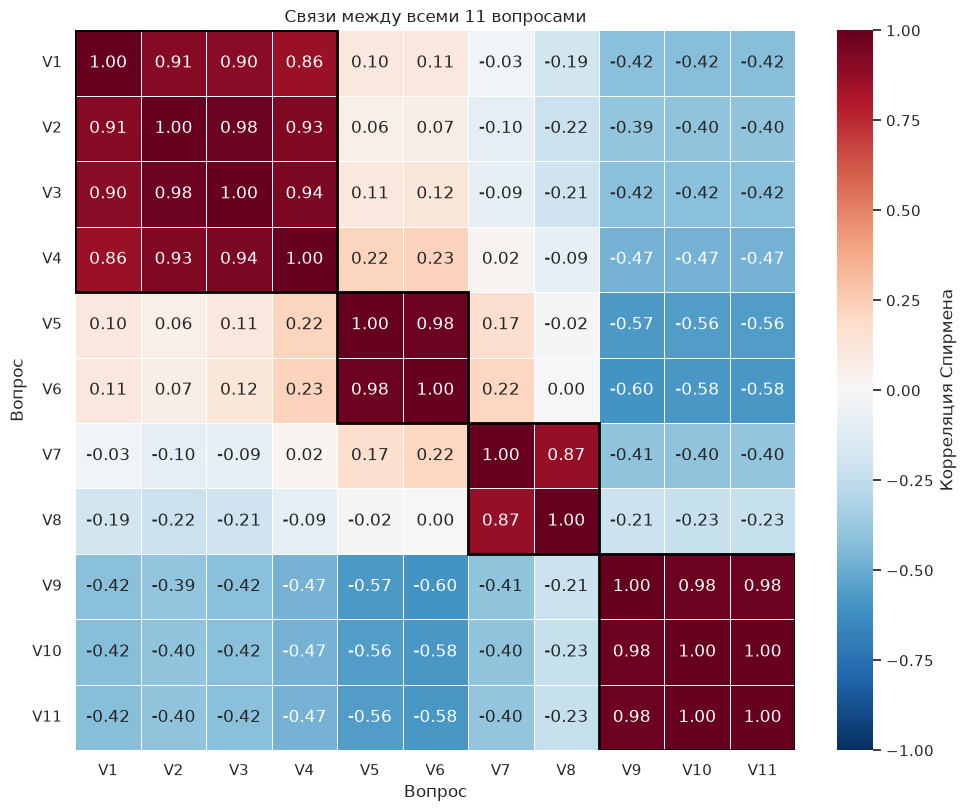

In [3]:
answer_counts = pd.DataFrame({column: data[column].value_counts()
                              for column in data.columns}).fillna(0).astype(int).sort_index()
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
sns.heatmap(answer_counts, annot=True, fmt="d", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "Число респондентов"})
ax.set(title="Распределение ответов по вопросам", xlabel="Вопрос", ylabel="Оценка")
ax.tick_params(axis="both", rotation=0)
plt.show()

themes = {
    "Свежесть и уверенность": ["V1", "V2", "V3", "V4"],
    "Сладкое": ["V5", "V6"],
    "Концентрация и пауза": ["V7", "V8"],
    "Самочувствие": ["V9", "V10", "V11"],
}
spearman = data.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.4, ax=ax,
            cbar_kws={"label": "Корреляция Спирмена"})
for columns in themes.values():
    start = data.columns.get_loc(columns[0])
    ax.add_patch(Rectangle((start, start), len(columns), len(columns),
                           fill=False, edgecolor="black", linewidth=2))
ax.set(title="Связи между всеми 11 вопросами", xlabel="Вопрос", ylabel="Вопрос")
ax.tick_params(axis="both", rotation=0)
plt.show()

Чёрные рамки выделяют темы, предложенные по формулировкам вопросов. Внутри них связи высокие: примерно 0,86–1,00. Это помогает обсуждать близкие мотивы вместе, но не делает вопросы одинаковыми.

**Все 11 вопросов остаются отдельными признаками.** Мы не заменяем их средними по темам. Рамки относятся к вопросам, а кластеры будут состоять из людей; число рамок не задаёт число групп.

### 2. Как работает DBSCAN

Для каждого человека алгоритм рассматривает соседей на расстоянии не больше `eps`. В этой работе расстояние евклидово и учитывает разницы по всем 11 ответам. Например, отличие на один балл в одном вопросе даёт расстояние 1, а в двух вопросах — примерно 1,41.

- **Основная точка**: в её окрестности есть не меньше `min_samples` наблюдений, включая её саму.
- **Граничная точка**: собственных соседей недостаточно, но она находится не дальше `eps` от основной точки.
- **Шум**: точка не является основной и не попала в окрестность ни одной основной точки. В модели её метка равна `-1`.

Алгоритм соединяет соседние основные точки в группы и присоединяет к ним граничные. Через цепочку основных точек кластер может быть шире `eps`: радиус ограничивает соседство, а не диаметр всей группы. Шум не считаем отдельным кластером.

Здесь нет начальных центров, `n_init` и заранее заданного `k`. Настраиваем `eps`, `min_samples`, метрику и подготовку признаков. Уменьшение радиуса или повышение `min_samples` делает требование к плотности строже. Однако число групп не обязано меняться монотонно: группы могут как появляться, так и исчезать.

В функциях ниже `frame` — таблица или массив признаков; `standardize` включает стандартизацию; `metric` задаёт расстояние. `fit_dbscan` возвращает обученную модель, `evaluate_model` — характеристики одного результата, `compare_parameters` — таблицу и словарь моделей всей серии. `compare_membership` сопоставляет состав двух разбиений и статус шума. Метки находятся в `labels_`, индексы основных точек — в `core_sample_indices_`.

In [4]:
def prepare_features(frame, standardize=False):
    """Вернуть числовой массив, при standardize=True стандартизовать столбцы."""
    return StandardScaler().fit_transform(frame) if standardize else np.asarray(frame, dtype=float)


def fit_dbscan(frame, eps, min_samples, metric="euclidean"):
    """Обучить DBSCAN с заданным радиусом и числом соседей, включая саму точку."""
    return DBSCAN(eps=eps, min_samples=min_samples, metric=metric).fit(frame)


def evaluate_model(frame, model, metric="euclidean"):
    """Описать разбиение; силуэт считать только для наблюдений вне шума."""
    values = np.asarray(frame)
    labels = model.labels_
    clustered = labels != -1
    sizes = pd.Series(labels[clustered]).value_counts().sort_values(ascending=False)
    n_clusters = len(sizes)
    silhouette = (silhouette_score(values[clustered], labels[clustered], metric=metric)
                  if 2 <= n_clusters < clustered.sum() else np.nan)
    return {
        "Кластеров": n_clusters,
        "Шум, чел.": int((~clustered).sum()),
        "Шум, %": (~clustered).mean() * 100,
        "Основных": len(model.core_sample_indices_),
        "Граничных": int(clustered.sum() - len(model.core_sample_indices_)),
        "Силуэт без шума": silhouette,
        "Минимальный размер": sizes.min() if n_clusters else 0,
        "Размеры групп": "/".join(sizes.astype(str)),
    }


def compare_parameters(frame, eps_values, min_samples_values, metric="euclidean"):
    """Вернуть таблицу показателей и модели, доступные по ключу (eps, min_samples)."""
    rows, models = [], {}
    for min_samples in min_samples_values:
        for eps in eps_values:
            model = fit_dbscan(frame, eps, min_samples, metric)
            models[(eps, min_samples)] = model
            rows.append({"eps": eps, "min_samples": min_samples,
                         **evaluate_model(frame, model, metric)})
    return pd.DataFrame(rows), models


def compare_membership(reference_labels, candidate_labels):
    """Вернуть ARI на общих нешумах и число изменений статуса шума."""
    common = (reference_labels != -1) & (candidate_labels != -1)
    ari = (adjusted_rand_score(reference_labels[common], candidate_labels[common])
           if common.sum() >= 2 else np.nan)
    return {"Общих объектов": int(common.sum()), "ARI на общих": ari,
            "Сменили статус шума": int(((reference_labels == -1) != (candidate_labels == -1)).sum())}


metric = "euclidean"
standardize = False
features = prepare_features(data, standardize=standardize)

### 3. Выбор радиуса и плотности

Начнём с `min_samples` из **5, 8, 10, 15 и 22**. Пять — мягкое требование; 8, 10 и 15 позволяют проверить промежуточные пороги; 22 — более строгая проверка, равная удвоенному числу признаков. Последнее — ориентир, а не обязательное правило: вопросы сильно связаны, и 11 столбцов не означают 11 независимых измерений. `min_samples` описывает локальное соседство и не задаёт размер готового сегмента.

Для каждого значения построим отсортированные расстояния до соответствующего соседа. В `kneighbors(frame)` явно передаём сам массив: тогда отсчёт включает саму точку, как в DBSCAN. Для `min_samples=10` смотрим десятое расстояние с учётом самой точки, а не десять других людей.

На таком графике обычно ищут заметный подъём расстояний. Но в нашей дискретной таблице много повторов, поэтому ожидаются нули и ступени. Один «идеальный локоть» может отсутствовать; график только помогает выбрать область для проверки.

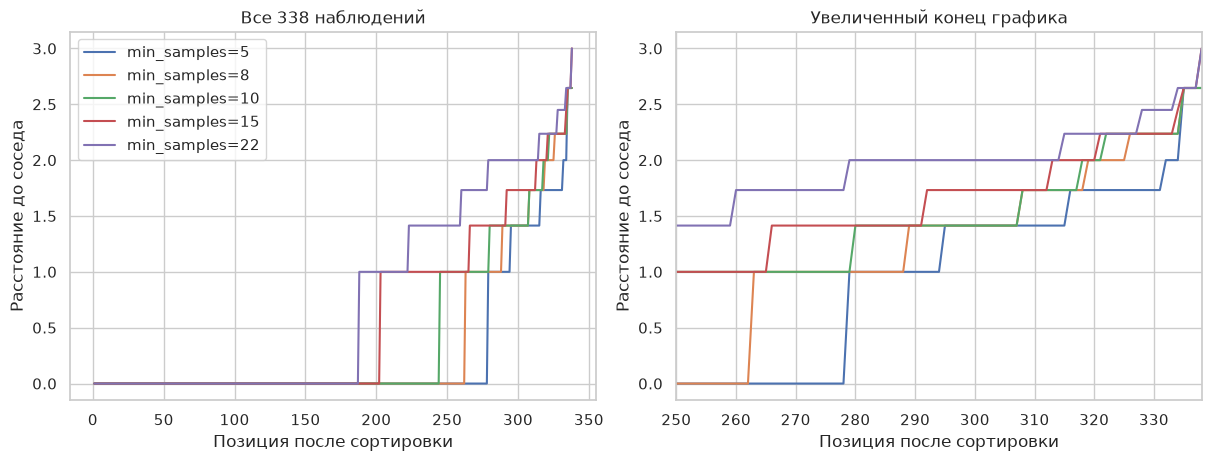

Нулевых расстояний при min_samples=10: 244


In [5]:
def neighbor_distances(frame, min_samples, metric="euclidean"):
    """Вернуть расстояния до min_samples-го соседа с учётом самой точки."""
    neighbors = NearestNeighbors(n_neighbors=min_samples, metric=metric).fit(frame)
    distances = neighbors.kneighbors(frame, return_distance=True)[0]
    return np.sort(distances[:, -1])


min_samples_values = [5, 8, 10, 15, 22]
neighbor_curves = {m: neighbor_distances(features, m, metric) for m in min_samples_values}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for min_samples, distances in neighbor_curves.items():
    for ax in axes:
        ax.plot(np.arange(1, len(data) + 1), distances, label=f"min_samples={min_samples}")
for ax in axes:
    ax.set(xlabel="Позиция после сортировки", ylabel="Расстояние до соседа")
axes[0].set_title("Все 338 наблюдений")
axes[1].set(title="Увеличенный конец графика", xlim=(250, len(data)))
axes[0].legend()
plt.show()
print("Нулевых расстояний при min_samples=10:", np.isclose(neighbor_curves[10], 0).sum())

При `min_samples=10` у **244 человек расстояние равно нулю**: у каждого хватает точно таких же ответов. Далее видны ступени около 1, 1,41, 1,73, 2 и выше. Они связаны с целыми оценками, а не с ошибкой графика.

Проверим радиусы от 0,5 до 3. Значение 0,5 показывает, что произойдёт, если соседями считать только одинаковые профили. Значения 1,5 и 1,8 расположены после ступеней 1,41 и 1,73; 2,0–3,0 позволяют увидеть дальнейшие слияния. Пока не выбираем число кластеров.

На картах сравним **число групп, долю шума и силуэт без шума**. В таблице усредняем его только по людям с меткой не `-1`.

Силуэт ближе к 1 означает лучшее разделение по этому критерию, но это не точность. При разном количестве шума он описывает разные подвыборки, поэтому максимизировать его в одиночку нельзя. Если кластеров меньше двух, значение оставляем неопределённым. Объединять все шумовые точки в один «пятый кластер» ради расчёта также неправильно.

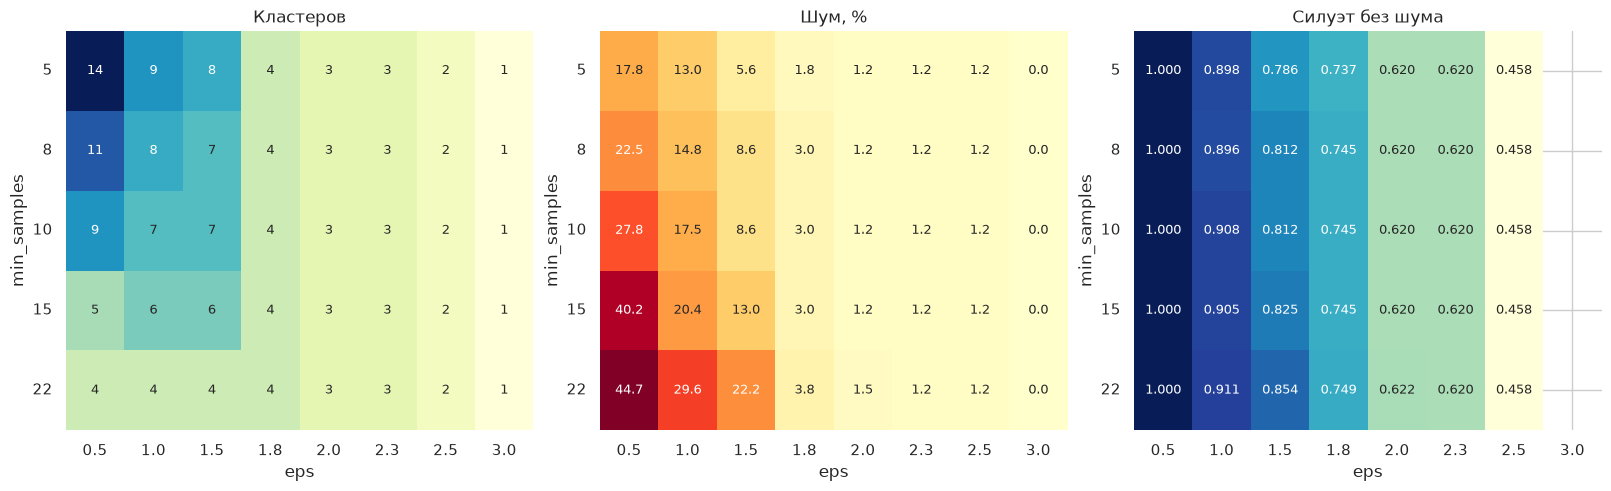

eps,Кластеров,"Шум, чел.","Шум, %",Силуэт без шума,Размеры групп
0.5,9,94,27.81,1.0000,52/49/49/37/15/12/10/10/10
1.0,7,59,17.46,0.9083,101/52/49/37/15/15/10
1.5,7,29,8.58,0.8116,104/59/54/46/16/15/15
1.8,4,10,2.96,0.7450,110/100/61/57
2.0,3,4,1.18,0.6201,120/110/104
2.3,3,4,1.18,0.6201,120/110/104
2.5,2,4,1.18,0.4577,230/104
3.0,1,0,0.00,—,338


In [6]:
eps_values = [0.5, 1.0, 1.5, 1.8, 2.0, 2.3, 2.5, 3.0]
results, models = compare_parameters(features, eps_values, min_samples_values, metric)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
plots = [("Кластеров", "d", "YlGnBu"),
         ("Шум, %", ".1f", "YlOrRd"),
         ("Силуэт без шума", ".3f", "YlGnBu")]
for ax, (column, number_format, palette) in zip(axes, plots):
    matrix = results.pivot(index="min_samples", columns="eps", values=column)
    sns.heatmap(matrix, annot=True, fmt=number_format, cmap=palette, ax=ax,
                annot_kws={"size": 9}, cbar=False, mask=matrix.isna())
    ax.set(title=column, xlabel="eps", ylabel="min_samples")
    ax.tick_params(axis="both", rotation=0)
plt.show()

comparison_columns = ["eps", "Кластеров", "Шум, чел.", "Шум, %",
                      "Силуэт без шума", "Размеры групп"]
display(results.loc[results["min_samples"] == 10, comparison_columns].style.format(
    {"eps": "{:.1f}", "Шум, %": "{:.2f}", "Силуэт без шума": "{:.4f}"}, na_rep="—").hide(axis="index"))

Карты показывают совместный перебор радиуса и пяти значений `min_samples`, включая 8. Для подробного просмотра радиуса временно берём серию `min_samples=10`, приведённую в таблице. Окончательный порог плотности выберем после сравнения профилей и отдельной таблицы `min_samples` ниже. Пустые клетки на карте силуэта означают, что он не определён, а не равен нулю.

При **`eps=0.5` силуэт равен 1**, но 94 человека попадают в шум, а девять групп состоят из массовых точных повторов. Внутри таких групп расстояния нулевые, поэтому показатель максимален. Для общего описания потребностей это слишком подробное и неполное решение.

При `eps=1.5` остаются семь групп и 29 шумовых наблюдений. При `eps=1.8` — четыре группы и 10 шумовых. При `eps=2.0` — три группы и четыре шумовых. При `eps=2.5` групп две, при 3,0 — одна. Уменьшение шума само по себе тоже не является целью: большой радиус может соединить разные потребности.

Область около 1,8 выглядит интересной: в кластеры входят 328 из 338 человек, а силуэт на них равен 0,7450. Теперь проверим по профилям, что именно меняется между ближайшими вариантами.

### 4. Что стоит за разным числом кластеров

На каждой карте строка — кластер, клетка — средняя оценка **одного вопроса среди людей этого кластера**. Это не усреднение разных вопросов. Карты имеют общую шкалу от 2 до 5; рядом с номером указано число людей, в заголовке — шум.

Для чтения увеличиваем неотрицательные метки на 1, а `-1` сохраняем для шума. Номер группы условный. Пересечения под картами покажут состав переходов по тем же людям, включая шумовые наблюдения.

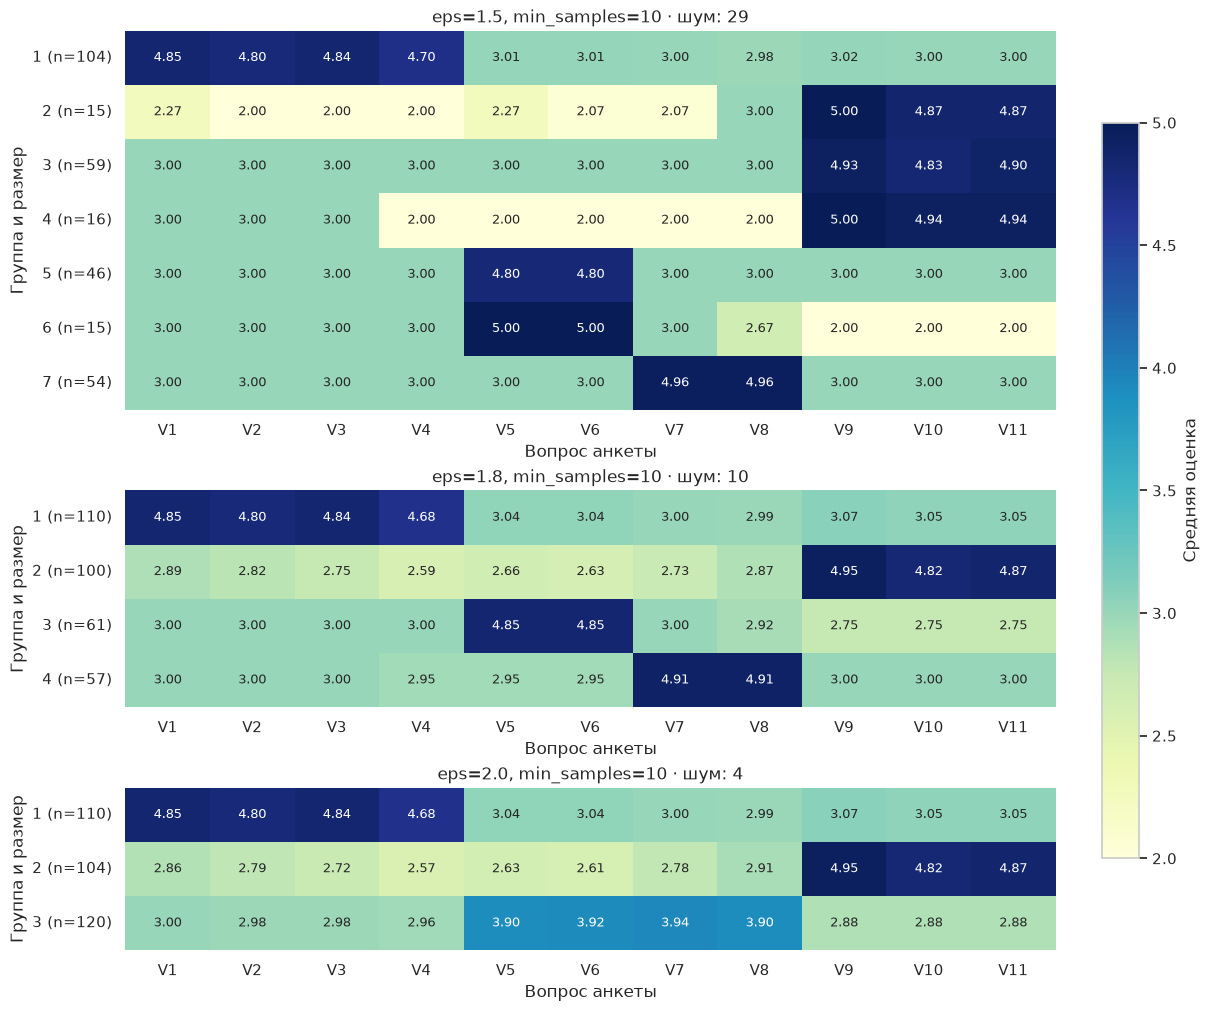

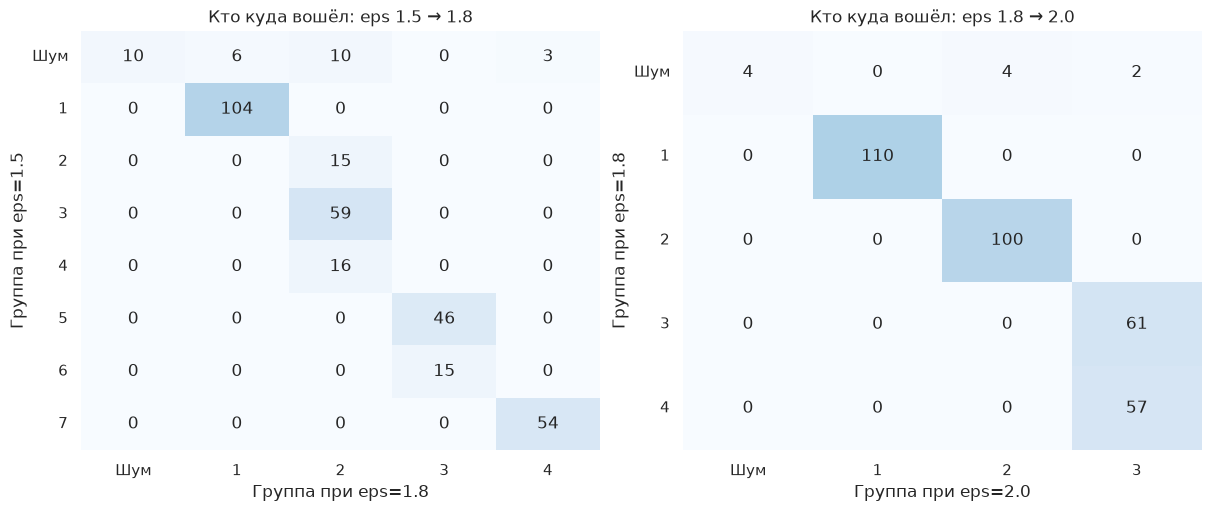

In [7]:
def plot_profile(frame, labels, ax, title, statistic="mean"):
    """Показать средние или медианы кластеров без шума; вернуть объект цветовой шкалы."""
    clustered = labels != -1
    groups = frame.loc[clustered].assign(cluster=labels[clustered] + 1).groupby("cluster")
    profile = groups.mean() if statistic == "mean" else groups.median()
    row_labels = [f"{group} (n={size})" for group, size in groups.size().items()]
    sns.heatmap(profile, annot=True, fmt=".2f", cmap="YlGnBu", vmin=2, vmax=5,
                yticklabels=row_labels, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set(title=title, xlabel="Вопрос анкеты", ylabel="Группа и размер")
    ax.tick_params(axis="both", rotation=0)
    return ax.collections[0]


candidate_eps = [1.5, 1.8, 2.0]
fig, axes = plt.subplots(3, 1, figsize=(12, 10),
                         gridspec_kw={"height_ratios": [7, 4, 3]}, constrained_layout=True)
for eps, ax in zip(candidate_eps, axes):
    candidate_labels = models[(eps, 10)].labels_
    color_source = plot_profile(data, candidate_labels, ax,
                                f"eps={eps}, min_samples=10 · шум: {(candidate_labels == -1).sum()}")
fig.colorbar(color_source, ax=axes.tolist(), shrink=0.8, label="Средняя оценка")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for (before, after), ax in zip([(1.5, 1.8), (1.8, 2.0)], axes):
    before_labels = models[(before, 10)].labels_
    after_labels = models[(after, 10)].labels_
    overlap = pd.crosstab(before_labels, after_labels)
    overlap = overlap.rename(index=lambda x: "Шум" if x == -1 else str(x + 1),
                             columns=lambda x: "Шум" if x == -1 else str(x + 1))
    sns.heatmap(overlap, annot=True, fmt="d", cmap="Blues", cbar=False,
                vmin=0, vmax=len(data), ax=ax)
    ax.set(title=f"Кто куда вошёл: eps {before} → {after}",
           xlabel=f"Группа при eps={after}", ylabel=f"Группа при eps={before}")
    ax.tick_params(axis="both", rotation=0)
plt.show()

При **`eps=1.5`** отдельно видны три подгруппы с высокими V9–V11 (59, 16 и 15 человек) и две со сладким (46 и 15). Это различия внутри общих ведущих мотивов. Ещё 29 человек пока не связаны с основными точками достаточно плотно.

При **`eps=1.8`** подтипы самочувствия объединяются в 100 человек, а сладкого — в 61. Сегмент свежести включает 110 человек, концентрации — 57. Пересечения показывают и переходы из шума: итог возникает не только из слияния уже готовых кластеров.

При **`eps=2.0`** сладкое и концентрация соединяются в группу из 120 человек: к прежним 61 и 57 добавляются два ранее шумовых наблюдения. В профиле теперь одновременно повышены V5–V8, хотя в предыдущем варианте у людей выделялись разные ведущие мотивы. Свежесть остаётся отдельной группой, самочувствие расширяется до 104 человек.

Эти профили поддерживают радиус `eps=1.8`: разные ведущие мотивы остаются разделены, а в группы входит большая часть выборки. Теперь при этом радиусе отдельно проверим требование к плотности, чтобы обосновать `min_samples`.

**Сравнение `min_samples` при `eps=1.8`.** Проверим 5, 8, 10, 15 и 22. В последнем столбце проверяется совпадение состава кластеров и набора шумовых анкет с вариантом 10. Для этого недостаточно одинаковых размеров: сравниваем метки тех же людей через ARI (при совпадении состава он равен 1) и отдельно проверяем, не изменился ли статус шума. Номера кластеров при сравнении не важны. Здесь 10 пока служит опорным вариантом, а не объявляется лучшим заранее.

In [8]:
# При фиксированном радиусе меняем только требование к плотности.
density_eps = 1.8
reference_labels = models[(density_eps, 10)].labels_
density_rows = []
for candidate_min_samples in min_samples_values:
    candidate = models[(density_eps, candidate_min_samples)]
    details = evaluate_model(features, candidate, metric)
    membership = compare_membership(reference_labels, candidate.labels_)
    same_membership = (membership["ARI на общих"] == 1
                       and membership["Сменили статус шума"] == 0)
    density_rows.append({
        "min_samples": candidate_min_samples,
        "Кластеров": details["Кластеров"],
        "Размеры групп": details["Размеры групп"],
        "Шум, чел.": details["Шум, чел."],
        "Состав и шум как при 10": "Да" if same_membership else "Нет",
    })
density_comparison = pd.DataFrame(density_rows)
display(density_comparison.style.hide(axis="index"))

min_samples,Кластеров,Размеры групп,"Шум, чел.",Состав и шум как при 10
5,4,110/104/61/57,6,Нет
8,4,110/100/61/57,10,Да
10,4,110/100/61/57,10,Да
15,4,110/100/61/57,10,Да
22,4,110/97/61/57,13,Нет


При **`min_samples=8, 10 и 15` совпадают состав четырёх кластеров и те же десять шумовых анкет**. При 5 в шуме остаются шесть человек, при 22 — тринадцать. То есть крайние проверенные пороги меняют статус части редких ответов, а промежуточные дают одно разбиение.

**Оставляем `min_samples=10` как рабочее значение внутри этого устойчивого участка:** небольшое ослабление требования до 8 и усиление до 15 не меняют сегменты. Для основной точки требуем десять близких наблюдений, включая её саму. Данные не показывают преимущества именно 10 перед 8 или 15 — любой из этих трёх порогов дал бы те же группы и шум. Мы также не утверждаем, что исключить ровно десять анкет объективно правильнее, чем шесть или тринадцать. Устойчивость здесь относится к составу кластеров и шуму; статус «основная/граничная» у отдельных точек может меняться.

Итак, основной вариант — **`eps=1.8`, `min_samples=10`**. Радиус выбран по охвату выборки и различиям профилей, а порог плотности — как представитель устойчивого промежуточного результата. **Четыре кластера получены алгоритмом**, отдельного параметра числа групп нет.

Радиус 1,8 допускает, например, разницу на один балл в трёх вопросах (расстояние около 1,73), но не разницу на два балла в одном вопросе (расстояние 2). Это масштаб локального соседства, а не ограничение различий между любыми двумя людьми кластера.

### 5. Итоговые сегменты, шум и проверки

Названия дадим по высоким значениям на карте `eps=1.8`. Они не участвовали в обучении. При изменении данных или параметров соответствие номеров этим названиям нужно проверить заново. Доли считаем от **всех 338 человек**, включая шум. Средние уже показаны, поэтому здесь приведём размеры и медианы. Шум отметим серым, но не будем называть его сегментом.

,Сегмент,Респондентов,"Доля, %"
Группа,,,
1,Свежесть и уверенность,110,32.54
2,Самочувствие,100,29.59
3,Сладкое,61,18.05
4,Концентрация и пауза,57,16.86
-1,Шум (вне кластеров),10,2.96


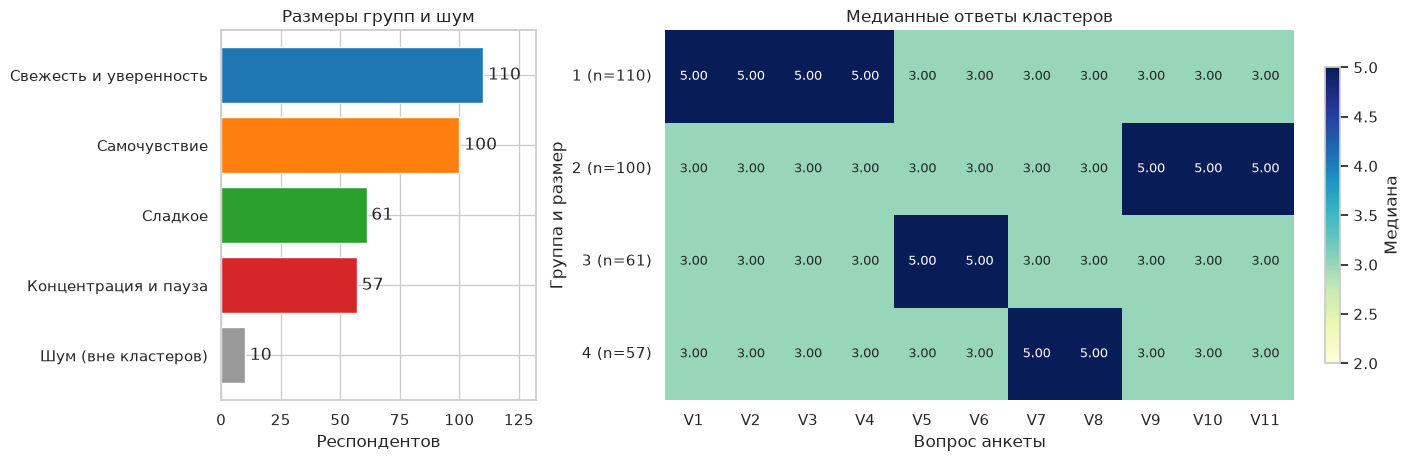

Типы точек: {'Основная': 317, 'Граничная': 11, 'Шум': 10}
В кластерах: 328, шум: 10; всего 338.


In [9]:
eps = 1.8
min_samples = 10
model = models[(eps, min_samples)]
labels = model.labels_
clustered = labels != -1
core_mask = np.zeros(len(data), dtype=bool)
core_mask[model.core_sample_indices_] = True
point_types = np.where(core_mask, "Основная", np.where(clustered, "Граничная", "Шум"))

sizes = pd.Series(labels[clustered] + 1).value_counts().sort_index()
segment_names = {1: "Свежесть и уверенность", 2: "Самочувствие",
                 3: "Сладкое", 4: "Концентрация и пауза"}
summary = pd.DataFrame({"Сегмент": pd.Series(segment_names), "Респондентов": sizes})
summary.loc[-1] = ["Шум (вне кластеров)", int((~clustered).sum())]
summary["Доля, %"] = summary["Респондентов"] / len(data) * 100
summary.index.name = "Группа"
display(summary.style.format({"Доля, %": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5),
                         gridspec_kw={"width_ratios": [1, 2]}, constrained_layout=True)
colors = list(sns.color_palette("tab10", len(sizes))) + ["#999999"]
axes[0].barh(summary["Сегмент"], summary["Респондентов"], color=colors)
for position, size in enumerate(summary["Респондентов"]):
    axes[0].text(size + 2, position, str(size), va="center")
axes[0].invert_yaxis()
axes[0].set(title="Размеры групп и шум", xlabel="Респондентов", xlim=(0, sizes.max() * 1.2))
color_source = plot_profile(data, labels, axes[1], "Медианные ответы кластеров", statistic="median")
fig.colorbar(color_source, ax=axes[1], shrink=0.8, label="Медиана")
plt.show()
print("Типы точек:", pd.Series(point_types).value_counts().to_dict())
print(f"В кластерах: {clustered.sum()}, шум: {(~clustered).sum()}; всего {len(data)}.")

Получились **свежесть и уверенность — 110 человек (32,54%)**, **самочувствие — 100 (29,59%)**, **сладкое — 61 (18,05%)**, **концентрация и пауза — 57 (16,86%)**. Вне кластеров остались **10 человек (2,96%)**. Из вошедших в группы 317 точек основные, 11 — граничные. Медианы ведущих вопросов равны 5, остальных — 3; это не означает, что так ответил каждый человек.

Эти группы позволяют предложить темы для дальнейшей проверки маркетинговых сообщений: свежесть, вкус, короткая пауза, ожидаемое облегчение симптомов. Анкета описывает мотивы и ожидания; она не доказывает лечебного эффекта, предпочтения марок или готовность платить.

**Что именно попало в шум?** Покажем все десять анкет на отдельной карте, без усреднения их между собой. «Респондент 113» означает 113-ю строку данных после заголовка, а не личный идентификатор. Для каждого найдём расстояние до ближайшей основной точки. Если оно больше выбранного радиуса, присоединить его как граничную точку нельзя. Ближайшую группу показываем только для объяснения: метку шума не меняем.

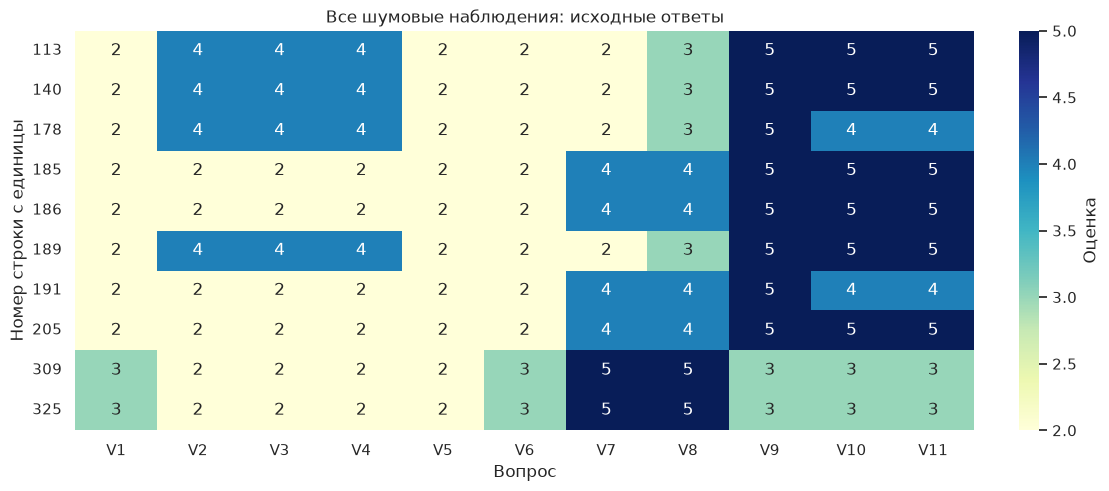

,Ближайший сегмент,Расстояние до основной точки
Респондент (номер строки),,
113,Самочувствие,2.646
140,Самочувствие,2.646
178,Самочувствие,2.646
185,Самочувствие,2.000
186,Самочувствие,2.000
189,Самочувствие,2.646
191,Самочувствие,2.000
205,Самочувствие,2.000
309,Концентрация и пауза,2.000


Разных профилей среди шумовых: 5


In [10]:
noise_mask = ~clustered
noise_data = data.loc[noise_mask].copy()
noise_data.index = noise_data.index + 1
noise_data.index.name = "Респондент (номер строки)"

if len(noise_data):
    fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
    sns.heatmap(noise_data, annot=True, fmt="d", cmap="YlGnBu", vmin=2, vmax=5,
                ax=ax, cbar_kws={"label": "Оценка"})
    ax.set(title="Все шумовые наблюдения: исходные ответы", xlabel="Вопрос",
           ylabel="Номер строки с единицы")
    ax.tick_params(axis="both", rotation=0)
    plt.show()

    distances = pairwise_distances(features[noise_mask], features[core_mask], metric=metric)
    nearest_positions = distances.argmin(axis=1)
    nearest_groups = labels[core_mask][nearest_positions] + 1
    noise_details = pd.DataFrame({
        "Ближайший сегмент": pd.Series(nearest_groups, index=noise_data.index).map(segment_names),
        "Расстояние до основной точки": distances.min(axis=1),
    }, index=noise_data.index)
    display(noise_details.style.format({"Расстояние до основной точки": "{:.3f}"}))
    print("Разных профилей среди шумовых:", len(noise_data.drop_duplicates()))
else:
    print("При выбранных параметрах шумовых наблюдений нет.")

На карте видны пять разных профилей. Их отличия от основных групп можно описать тремя случаями; внутри первых двух случаев немного различаются ответы V10–V11:

- Строки **113, 140, 178 и 189**: высокие V9–V11 сочетаются с V2–V4=4, но V1=2. Ближайшая основная точка самочувствия находится на расстоянии около 2,646.
- Строки **185, 186, 191 и 205**: высокие V9–V11 сочетаются с V7–V8=4, а V1–V6=2. Расстояние до ближайшей основной точки самочувствия равно 2.
- Строки **309 и 325**: V7–V8=5, но V2–V5=2. До ближайшей основной точки концентрации также расстояние 2.

Каждое из этих расстояний больше 1,8. Такие сочетания ответов допустимы, но в выбранном радиусе им не хватает плотного окружения. Шум здесь не означает ошибку анкеты, «плохого клиента» или отсутствие потребностей. Это десять сохранённых наблюдений, которые текущие параметры не присоединили к группам. Их нельзя объединять в содержательный пятый сегмент только из-за общей метки `-1`.

**Насколько выбор устойчив?** Пороги `min_samples` уже сопоставлены перед итоговым выбором. Теперь проверим соседние радиусы при `min_samples=10` и перестановки строк. Для оценки состава используем ARI: он равен 1 при совпадении разбиений независимо от номеров групп. ARI считаем только по людям, вошедшим в кластеры в обоих вариантах, а изменения статуса шума учитываем отдельно. Так шум не превращается в искусственный общий кластер для сравнения.

In [11]:
nearby_settings = [(1.7, 10), (1.75, 10), (1.85, 10), (1.95, 10), (2.0, 10)]
sensitivity_rows = []
for candidate_eps, candidate_min_samples in nearby_settings:
    candidate = fit_dbscan(features, candidate_eps, candidate_min_samples, metric)
    details = evaluate_model(features, candidate, metric)
    sensitivity_rows.append({"eps": candidate_eps, "min_samples": candidate_min_samples,
                             "Кластеров": details["Кластеров"], "Шум, чел.": details["Шум, чел."],
                             **compare_membership(labels, candidate.labels_)})
display(pd.DataFrame(sensitivity_rows).style.format(
    {"eps": "{:.2f}", "ARI на общих": "{:.4f}"}).hide(axis="index"))

# Проверяем порядок строк; после расчёта возвращаем метки к исходным респондентам.
order_checks = []
for seed in range(5):
    order = np.random.default_rng(seed).permutation(len(data))
    shuffled_model = fit_dbscan(features[order], eps, min_samples, metric)
    restored_labels = np.empty(len(data), dtype=int)
    restored_labels[order] = shuffled_model.labels_
    order_checks.append(compare_membership(labels, restored_labels))
print("Минимальный ARI в пяти перестановках:", min(row["ARI на общих"] for row in order_checks))
print("Максимум изменений статуса шума:", max(row["Сменили статус шума"] for row in order_checks))

eps,min_samples,Кластеров,"Шум, чел.",Общих объектов,ARI на общих,Сменили статус шума
1.70,10,7,29,309,0.8401,19
1.75,10,4,10,328,1.0000,0
1.85,10,4,10,328,1.0000,0
1.95,10,4,10,328,1.0000,0
2.00,10,3,4,328,0.8465,6


Минимальный ARI в пяти перестановках: 1.0
Максимум изменений статуса шума: 0


На проверенных радиусах **1,75, 1,85 и 1,95** при `min_samples=10` состав и шум совпали с основным вариантом. При 1,7 ещё семь групп, при 2,0 уже три: выбранный результат устойчив локально, но не к произвольному изменению радиуса. Ступени объясняются дискретными расстояниями; 1,8 не является единственной подходящей точкой.

Пять перестановок строк также сохранили состав кластеров и набор шумовых наблюдений.

У DBSCAN нет случайной инициализации, но в общем случае пограничная точка может быть доступна из двух разных кластеров; тогда её назначение зависит от порядка просмотра. Поэтому проверка перестановок осмысленна. Здесь такого изменения в проверенных порядках не возникло.

**Влияние стандартизации.** Теперь вычтем среднее каждого вопроса и разделим на его стандартное отклонение. В новой шкале расстояния изменятся, поэтому нельзя автоматически сохранять прежний радиус. Покажем кривую расстояний и небольшую серию радиусов при том же `min_samples=10`. Размеры и шум можно сопоставлять с исходным решением; силуэты разных шкал напрямую не сравниваем.

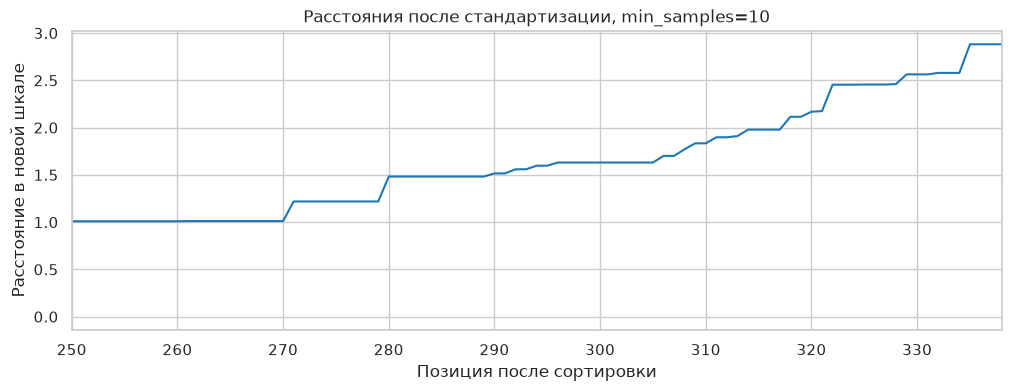

eps в новой шкале,Кластеров,"Шум, чел.",Общих объектов,ARI на общих,Сменили статус шума
1.5,7,49,289,0.8580,39
1.8,6,25,313,0.8943,15
1.9,5,13,325,0.9332,3
2.0,4,10,328,1.0000,0
2.1,4,10,328,1.0000,0
2.2,4,8,328,1.0000,2
2.3,4,4,328,1.0000,6
2.4,3,4,328,0.8465,6
2.6,2,4,328,0.4261,6
3.2,1,0,328,0.0000,10


In [12]:
scaled_features = prepare_features(data, standardize=True)
scaled_distances = neighbor_distances(scaled_features, min_samples, metric)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(np.arange(1, len(data) + 1), scaled_distances, color="#1f77b4")
ax.set(title="Расстояния после стандартизации, min_samples=10", xlim=(250, len(data)),
       xlabel="Позиция после сортировки", ylabel="Расстояние в новой шкале")
plt.show()

scaled_eps_values = [1.5, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3, 2.4, 2.6, 3.2]
scaled_results, scaled_models = compare_parameters(scaled_features, scaled_eps_values,
                                                   [min_samples], metric)
scaled_comparison = []
for candidate_eps in scaled_eps_values:
    candidate = scaled_models[(candidate_eps, min_samples)]
    details = evaluate_model(scaled_features, candidate, metric)
    scaled_comparison.append({"eps в новой шкале": candidate_eps,
                              "Кластеров": details["Кластеров"], "Шум, чел.": details["Шум, чел."],
                              **compare_membership(labels, candidate.labels_)})
display(pd.DataFrame(scaled_comparison).style.format(
    {"eps в новой шкале": "{:.1f}", "ARI на общих": "{:.4f}"}).hide(axis="index"))

С прежним `eps=1.8` в новой шкале получаются **шесть кластеров и 25 шумовых**, то есть масштаб действительно влияет. При радиусах **2,0 и 2,1** получается тот же состав четырёх групп и те же десять шумовых анкет. При 2,2–2,3 ещё четыре группы, но часть шума уже присоединяется; при 2,4 начинается слияние разных мотивов.

Таким образом, знакомая структура воспроизводится и в новой шкале при пересмотре радиуса. Это дополнительная проверка, а не доказательство нечувствительности DBSCAN к масштабу или универсальности четырёх сегментов. В качестве основного оставляем исходную общую шкалу и уже объяснённый радиус 1,8.

**Сопоставление со второй работой.** Для проверки заново рассчитаем k-means с прежними настройками. Сравним состав только на 328 людях, которых DBSCAN включил в кластеры. Это проверка уже выбранного решения, а не способ подобрать параметры DBSCAN под ответ предыдущей лабораторной.

In [13]:
kmeans_model = KMeans(n_clusters=4, init="k-means++", n_init=100,
                      random_state=42, max_iter=300, tol=1e-4, algorithm="lloyd").fit(data)
print("Респондентов в сравнении:", clustered.sum())
print("ARI: DBSCAN и k-means на нешумах:",
      adjusted_rand_score(labels[clustered], kmeans_model.labels_[clustered]))

Респондентов в сравнении: 328
ARI: DBSCAN и k-means на нешумах: 1.0


На этих 328 людях ARI равен **1**: состав четырёх групп совпадает, хотя их номера могут различаться. Разница методов проявилась в том, что DBSCAN оставил десять редких сочетаний вне кластеров, а k-means распределяет всех. Силуэт DBSCAN 0,7450 рассчитан без шума, а 0,7265 из второй работы — на всех 338 людях; эти числа не доказывают превосходства одного метода.

### 6. Выводы и ограничения

DBSCAN при `eps=1.8`, `min_samples=10` выделил **четыре кластера и десять шумовых наблюдений**. Кластеры описывают свежесть и уверенность, самочувствие, сладкое, концентрацию и паузу. Выбор параметров опирается на соседние расстояния, охват выборки, профили и чувствительность к настройкам; число групп получено алгоритмом.

Шумовые ответы допустимы и содержательно объяснимы. Мы сохранили их и показали отдельно, не присваивая им кластер принудительно. Более строгие или мягкие параметры меняют статус части этих анкет.

Результат относится к этой выборке. Баллы порядковые, но расстояния предполагают равные интервалы; связанные вопросы усиливают вклад отдельных тем. Множество повторов существенно влияет на оценку плотности. Один радиус может плохо описывать группы разной плотности, а силуэт без шума не оценивает оставшихся людей. Проверки на новой выборке нет, поэтому найденные сегменты и маркетинговые идеи требуют дальнейшего исследования.